<a href="https://colab.research.google.com/github/az47202922-tech/python-notebook/blob/main/Proton_2state_HMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proton Bonding State Analysis with a Two-State Mixed-Emission HMM

Experimental variant: Upper-gap state uses smoothed uniform gap and a two-Gaussian angle mixture. State 0 retains the full-covariance Gaussian.

**Original notebook is not modified.**


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, glob, re, time, warnings
from google.colab import files

DT_FS = None
SEED = 42
ARC_PATH = None

print("Select one ARC trajectory file:")
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Upload exactly one ARC file.")

file_name = next(iter(uploaded))
if Path(file_name).suffix.lower() != ".arc":
    raise ValueError("The selected file must have an .arc extension.")

arc_path = Path(file_name)
if not arc_path.is_file() or arc_path.stat().st_size == 0:
    raise ValueError("The uploaded file is missing or empty.")

while True:
    try:
        frame_interval = float(input("Enter the saved-frame interval (1 frame = ? fs): "))
        if not np.isfinite(frame_interval) or frame_interval <= 0:
            raise ValueError
    except ValueError:
        print("Please enter a finite number greater than zero (e.g., 1 or 0.5).")
        continue
    DT_FS = frame_interval
    break

ARC_PATH = arc_path

print(f"ARC file: {ARC_PATH}")
print(f"File size: {ARC_PATH.stat().st_size / 1_000_000:.2f} MB")
print(f"Saved-frame interval: 1 frame = {DT_FS:g} fs")
print(f"Random seed: {SEED}")


Select one ARC trajectory file:


Saving H2O2-FeNO3-aqua-500k-900fs.arc to H2O2-FeNO3-aqua-500k-900fs.arc
Enter the saved-frame interval (1 frame = ? fs): 1
ARC file: H2O2-FeNO3-aqua-500k-900fs.arc
File size: 26.16 MB
Saved-frame interval: 1 frame = 1 fs
Random seed: 42


# [2] Read trajectory File


In [ ]:
def cell_matrix(a, b, c, alpha, beta, gamma):
  al, be, ga = np.deg2rad([alpha, beta, gamma])
  ax = [a, 0.0, 0.0]
  bx = [b * np.cos(ga), b * np.sin(ga), 0.0]
  cx = c * np.cos(be)
  cy = c * (np.cos(al) - np.cos(be) * np.cos(ga)) / np.sin(ga)
  cz = np.sqrt(max(c * c - cx * cx - cy * cy, 0.0))
  return np.array([ax, bx, [cx, cy, cz]])

def read_arc(path):
    frames = []          # each frame: dict(cell, ids, elements, xyz)
    cell, ids, elems, xyz = None, [], [], []
    def flush():
        if ids:
            order = np.argsort(ids)
            frames.append({
                "cell": cell,
                "ids": np.asarray(ids)[order],
                "elements": np.asarray(elems)[order],
                "xyz": np.asarray(xyz, dtype=float)[order],
            })
    with open(path, encoding="utf-8", errors="replace") as fh:
        for line in fh:
            s = line.strip()
            if s.startswith("!DATE"):
                flush()
                cell, ids, elems, xyz = None, [], [], []
                continue
            if not s or s.startswith("!") or s.lower() == "end":
                continue
            t = s.split()
            if t[0].upper() == "PBC" and len(t) >= 7:
                cell = cell_matrix(*map(float, t[1:7]))
                continue
            m = re.match(r"^([A-Za-z]+)(\d+)$", t[0])
            if m and len(t) >= 4:
                ids.append(int(m.group(2)))
                elem = t[-2] if len(t) >= 8 else m.group(1)
                elems.append(elem[:1].upper() + elem[1:].lower())
                xyz.append([float(t[1]), float(t[2]), float(t[3])])
    flush()
    return frames

t0 = time.time()
frames = read_arc(ARC_PATH)
f0 = frames[0]
print(f"Read {len(frames)} frames ({time.time() - t0:.1f} s)")
print("Atom composition of first frame:", pd.Series(f0["elements"]).value_counts().to_dict())
print("PBC cell matrix (Å):\n", np.round(f0["cell"], 4))

Read 900 frames (1.9 s)
Atom composition of first frame: {'H': 220, 'O': 122, 'N': 3, 'Fe': 1}
PBC cell matrix (Å):
 [[15.4583  0.      0.    ]
 [ 0.0641 15.2762  0.    ]
 [ 0.0417  0.1736 15.3772]]


# [3] Compute r1、r2 and O1-H-O2 angle of each H atom

In [ ]:
# [3] Compute r1, r2 for each H (nearest and second-nearest O, minimum-image distance) and the O1–H–O2 angle (H at the vertex)
def h_geometry(frames):
    rows = []
    for k, fr in enumerate(frames, start=1):
        ids, el, xyz = fr["ids"], fr["elements"], fr["xyz"]
        h_mask, o_mask = el == "H", el == "O"
        H, O = xyz[h_mask], xyz[o_mask]
        h_ids, o_ids = ids[h_mask], ids[o_mask]
        M = fr["cell"]; Minv = np.linalg.inv(M)
        d = O[None, :, :] - H[:, None, :]
        f = d @ Minv
        d = (f - np.round(f)) @ M
        r = np.linalg.norm(d, axis=2)
        order = np.argsort(r, axis=1, kind="stable")[:, :2]
        i = np.arange(len(H))
        v1, v2 = d[i, order[:, 0]], d[i, order[:, 1]]
        r1, r2 = r[i, order[:, 0]], r[i, order[:, 1]]
        cosang = np.clip(np.sum(v1 * v2, axis=1) / np.maximum(r1 * r2, 1e-8), -1, 1)
        rows.append(pd.DataFrame({
            "H_ID": h_ids, "Frame": k,
            "O1_ID": o_ids[order[:, 0]], "O2_ID": o_ids[order[:, 1]],
            "r1_A": r1, "r2_A": r2,
            "O1_H_O2_angle_deg": np.degrees(np.arccos(cosang)),
        }))
    data = pd.concat(rows, ignore_index=True)
    data["gap_A"] = (data["r2_A"] - data["r1_A"]).clip(lower=0.0)
    return data.sort_values(["H_ID", "Frame"]).reset_index(drop=True)

t0 = time.time()
data = h_geometry(frames)
print(f"Total: {data['H_ID'].nunique()} H × {data['Frame'].nunique()} frames = {len(data)} rows ({time.time() - t0:.1f} s)")

from IPython.display import display
summary = (data[["r1_A", "r2_A", "gap_A", "O1_H_O2_angle_deg"]]
           .describe()
           .rename(columns={"gap_A": "Δr"}))
display(summary.style
        .format("{:.3f}")
        .format("{:.0f}", subset=pd.IndexSlice[["count"], :])
        .set_properties(**{"text-align": "center"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))

Total: 220 H × 900 frames = 198000 rows (3.7 s)


,r1_A,r2_A,Δr,O1_H_O2_angle_deg
count,198000,198000,198000,198000
mean,1.060,1.820,0.760,149.240
std,0.072,0.526,0.577,29.826
min,0.874,1.134,0.000,22.105
25%,1.006,1.405,0.305,144.726
50%,1.047,1.625,0.583,159.187
75%,1.106,2.163,1.156,167.368
max,1.371,3.392,2.427,179.970


# [4] Train-Test Split and Feature Standardization


In [ ]:
# Observation features: nearest O distance, distance gap, and O-H-O angle.
FEATURES = ["r1_A", "gap_A", "O1_H_O2_angle_deg"]
TRAIN_RATIO = 0.7

# Split by H_ID so all frames of each H remain in the same subset.
h_ids = np.sort(data["H_ID"].unique())
rng = np.random.default_rng(SEED)
shuffled_ids = rng.permutation(h_ids)
n_train = int(round(TRAIN_RATIO * len(h_ids)))
train_ids = np.sort(shuffled_ids[:n_train])
test_ids = np.sort(shuffled_ids[n_train:])

# Array shape: (H trajectories, frames, features).
by_h = {h: group.sort_values("Frame") for h, group in data.groupby("H_ID")}
def arrange(ids):
    return np.stack([by_h[h][FEATURES].to_numpy(dtype=float) for h in ids])

train_raw = arrange(train_ids)
test_raw = arrange(test_ids)

# Fit scaling parameters on the training set, then apply them to both sets.
flat_train = train_raw.reshape(-1, len(FEATURES))
feat_mean = flat_train.mean(axis=0)
feat_std = flat_train.std(axis=0)
if np.any(feat_std == 0):
    raise ValueError("A training feature has zero standard deviation.")

train_x = (train_raw - feat_mean) / feat_std
test_x = (test_raw - feat_mean) / feat_std

print(f"Training H atoms: {len(train_ids)}; test H atoms: {len(test_ids)}")
print(f"train_x shape: {train_x.shape}; test_x shape: {test_x.shape}")
print("Shape: (H trajectories, frames, features)")
print(f"Model features: {FEATURES}")

# Summarize all four raw geometry columns using training H atoms only.
STAT_COLUMNS = ["r1_A", "r2_A", "gap_A", "O1_H_O2_angle_deg"]
train_values = data.loc[data["H_ID"].isin(train_ids), STAT_COLUMNS]
train_stats = train_values.describe().rename(columns={"gap_A": "Δr"})
train_stats.loc["variance"] = train_values.var(ddof=0).to_numpy()
train_stats = train_stats.loc[
    ["count", "mean", "std", "variance", "min", "25%", "50%", "75%", "max"]
]
print("Training feature statistics (before standardization):")
display(train_stats.style
        .format("{:.3f}")
        .format("{:.0f}", subset=pd.IndexSlice[["count"], :])
        .set_properties(**{"text-align": "center"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]))


Training H atoms: 154; test H atoms: 66
train_x shape: (154, 900, 3); test_x shape: (66, 900, 3)
Shape: (H trajectories, frames, features)
Model features: ['r1_A', 'gap_A', 'O1_H_O2_angle_deg']
Training feature statistics (before standardization):


,r1_A,r2_A,Δr,O1_H_O2_angle_deg
count,138600,138600,138600,138600
mean,1.057,1.832,0.775,149.257
std,0.071,0.519,0.570,29.544
variance,0.005,0.270,0.324,872.823
min,0.874,1.138,0.000,22.105
25%,1.004,1.418,0.323,144.564
50%,1.044,1.648,0.610,158.888
75%,1.101,2.180,1.175,167.208
max,1.371,3.392,2.390,179.970


## [4B] Pairwise Scatter Plots of All Raw Training Observations


Raw pairwise plots: 138,600 / 138,600 training observations (100%; no sampling)


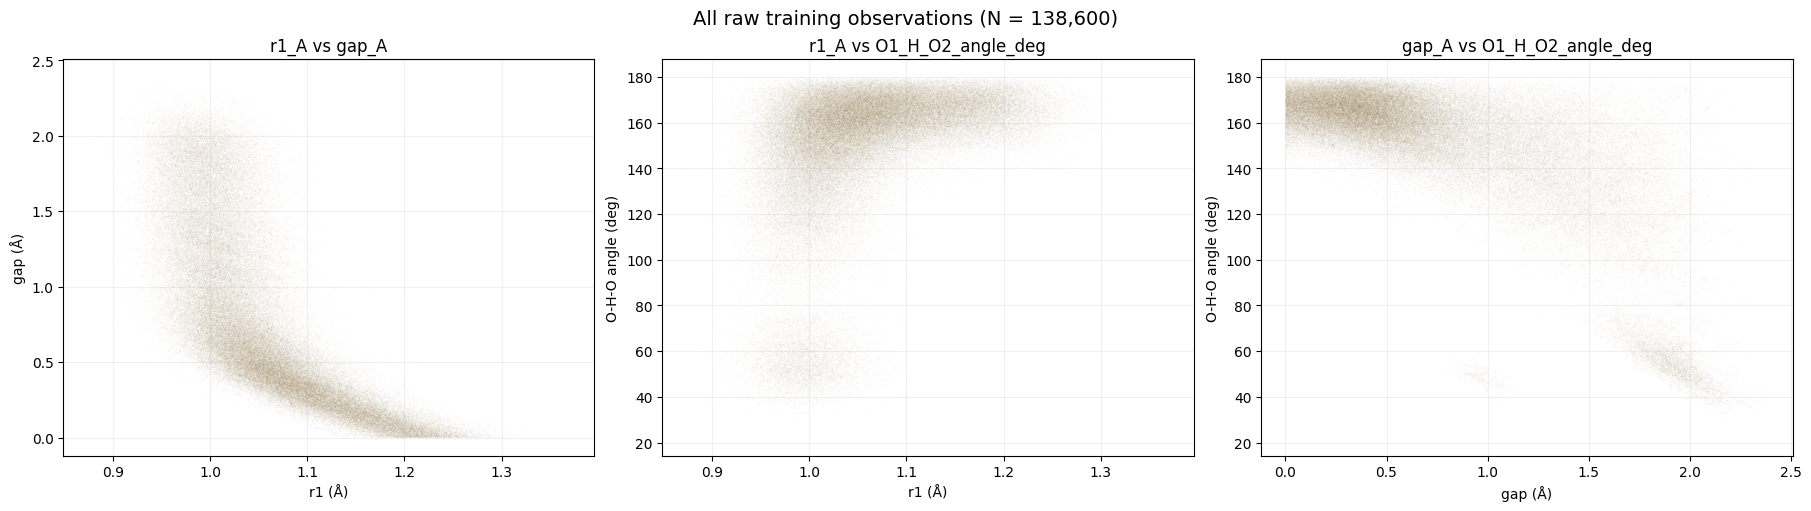

In [ ]:
# [4B] Pairwise 2D scatter plots using 100% of raw (unstandardized) training observations.
# No random sampling or HMM state labels are applied.
import matplotlib.pyplot as plt

X_pair_raw = train_raw.reshape(-1, len(FEATURES))
if X_pair_raw.shape[1] != 3:
    raise ValueError(f"Expected 3 features, found {X_pair_raw.shape[1]}")
if not np.isfinite(X_pair_raw).all():
    raise ValueError("Non-finite values detected in raw training data.")

feature_labels_raw = ["r1 (Å)", "gap (Å)", "O-H-O angle (deg)"]
feature_pairs = [(0, 1), (0, 2), (1, 2)]

print(f"Raw pairwise plots: {X_pair_raw.shape[0]:,} / {X_pair_raw.shape[0]:,} training observations (100%; no sampling)")
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
for ax, (i, j) in zip(axes, feature_pairs):
    ax.scatter(X_pair_raw[:, i], X_pair_raw[:, j], s=0.6, alpha=0.045,
               c="#8c6d31", edgecolors="none", rasterized=True)
    ax.set_xlabel(feature_labels_raw[i])
    ax.set_ylabel(feature_labels_raw[j])
    ax.set_title(f"{FEATURES[i]} vs {FEATURES[j]}")
    ax.grid(True, alpha=0.18)
fig.suptitle(f"All raw training observations (N = {len(X_pair_raw):,})", fontsize=14)
plt.show()


# [5] Two-State HMM: State 0 Full Gaussian; State 1 Smoothed Uniform Gap + Bimodal Angle

In [ ]:
# Mixed-emission HMM: state 0 = trivariate Gaussian;
# state 1 = independent r1 Gaussian * smoothed-uniform gap * two-Gaussian angle mixture.
# Independence of the three state-1 features is an explicit modeling assumption.
from scipy.special import ndtr, logsumexp
from scipy.stats import norm
N_STATES, COV_FLOOR = 2, 1e-4
GAP_IDX = FEATURES.index("gap_A")
ANGLE_IDX = FEATURES.index("O1_H_O2_angle_deg")
R1_IDX = FEATURES.index("r1_A")

def weighted_moments(x, w, floor=COV_FLOOR):
    total = max(np.sum(w), 1e-12)
    mean = np.sum(w*x)/total
    var = max(np.sum(w*(x-mean)**2)/total, floor)
    return float(mean), float(var)

def initialize_extra(x_state):
    # Input in standardized coordinates; upper-quarter samples only.
    gap = x_state[:, GAP_IDX]
    angle = x_state[:, ANGLE_IDX]
    left, right = np.quantile(gap, [0.03, 0.97])
    sigma = max(0.08 * np.std(gap), 0.035)
    mid = np.quantile(angle, 0.5)
    a0, a1 = angle[angle <= mid], angle[angle > mid]
    if min(len(a0), len(a1)) < 2:
        raise ValueError("Not enough angular observations for two components")
    return {
        'gap_left': float(left), 'gap_right': float(max(right, left+0.1)),
        'gap_smooth': float(sigma),
        'angle_weights': np.array([0.5, 0.5]),
        'angle_means': np.array([a0.mean(), a1.mean()]),
        'angle_vars': np.maximum([a0.var(), a1.var()], 0.04),
    }

def initialize_hmm(x):
    flat = x.reshape(-1, x.shape[-1])
    order = np.argsort(flat[:, GAP_IDX], kind='stable')
    q = len(order)//4
    low, high = flat[order[:q]], flat[order[-q:]]
    means = np.stack([low.mean(axis=0), high.mean(axis=0)])
    pooled = np.cov(flat, rowvar=False, bias=True) + COV_FLOOR*np.eye(x.shape[-1])
    covs = np.repeat(pooled[None, :, :], N_STATES, axis=0)
    covs[0] = np.cov(low, rowvar=False, bias=True) + COV_FLOOR*np.eye(x.shape[-1])
    return np.array([.5,.5]), np.array([[.95,.05],[.05,.95]]), means, covs, initialize_extra(high)

def log_emission(x, means, covariances, extra):
    n_h, n_frames, n_features = x.shape
    out = np.empty((n_h,n_frames,2))
    # State 0 full-covariance Gaussian.
    L = np.linalg.cholesky(covariances[0])
    centered = (x-means[0]).reshape(-1,n_features)
    z = np.linalg.solve(L,centered.T)
    out[:,:,0] = (-0.5*(n_features*np.log(2*np.pi) +
                           2*np.log(np.diag(L)).sum() +
                           np.sum(z*z,axis=0))).reshape(n_h,n_frames)
    # State 1: smoothed uniform is a proper PDF on the entire real line,
    # unlike a hard uniform whose zero density would break HMM inference.
    gap = x[:,:,GAP_IDX]
    left,right,sigma = extra['gap_left'],extra['gap_right'],extra['gap_smooth']
    gap_pdf = (ndtr((gap-left)/sigma)-ndtr((gap-right)/sigma))/(right-left)
    gap_log = np.log(np.maximum(gap_pdf,1e-300))
    r1 = x[:,:,R1_IDX]
    r1_log = norm.logpdf(r1,means[1,R1_IDX],np.sqrt(max(covariances[1,R1_IDX,R1_IDX],COV_FLOOR)))
    angle = x[:,:,ANGLE_IDX]
    mix = np.stack([np.log(max(extra['angle_weights'][k],1e-12)) +
                    norm.logpdf(angle,extra['angle_means'][k],np.sqrt(extra['angle_vars'][k]))
                    for k in range(2)],axis=-1)
    out[:,:,1] = r1_log + gap_log + logsumexp(mix,axis=-1)
    return out

start,trans,means,covariances,extra = initialize_hmm(train_x)
print('Initial standardized means:')
display(pd.DataFrame(means,columns=FEATURES,index=['State 0','State 1']).round(3))
print('State 1 smoothed-uniform gap bounds:',extra['gap_left'],extra['gap_right'])
print('State 1 angle mixture means:',extra['angle_means'])

Initial standardized means:


,r1_A,gap_A,O1_H_O2_angle_deg
State 0,1.316,-1.061,0.544
State 1,-0.853,1.481,-1.102


State 1 smoothed-uniform gap bounds: 0.7455363863720714 2.3323645599081653
State 1 angle mixture means: [-2.15882391 -0.04469652]


# [6] Forward-Backward: State and Transition Probabilities


In [ ]:
from scipy.special import logsumexp

def forward_backward(x, start, trans, means, covariances, extra):
    # Each H trajectory starts independently with the same initial distribution.
    emission = log_emission(x, means, covariances, extra)
    n_h, n_frames, n_states = emission.shape
    log_start = np.log(start)
    log_trans = np.log(trans)

    # Forward: evidence from the first frame through the current frame.
    forward = np.empty_like(emission)
    forward[:, 0, :] = log_start + emission[:, 0, :]
    for t in range(1, n_frames):
        forward[:, t, :] = emission[:, t, :] + logsumexp(
            forward[:, t - 1, :, None] + log_trans[None, :, :], axis=1
        )
    log_likelihood = logsumexp(forward[:, -1, :], axis=1)

    # Backward: evidence from future frames.
    backward = np.zeros_like(emission)
    for t in range(n_frames - 2, -1, -1):
        backward[:, t, :] = logsumexp(
            log_trans[None, :, :]
            + emission[:, t + 1, None, :]
            + backward[:, t + 1, None, :],
            axis=2,
        )

    # gamma[h, t, s] = P(state s at t | the entire H trajectory).
    gamma = np.exp(forward + backward - log_likelihood[:, None, None])

    # xi[h, t, i, j] = P(i at t, j at t+1 | the entire H trajectory).
    xi = np.exp(
        forward[:, :-1, :, None]
        + log_trans[None, None, :, :]
        + emission[:, 1:, None, :]
        + backward[:, 1:, None, :]
        - log_likelihood[:, None, None, None]
    )
    return log_likelihood, gamma, xi

# [7] M-Step: Update HMM Parameters


In [ ]:
def update_hmm(x, gamma, xi, extra, covariance_floor=COV_FLOOR):
    weights = gamma.sum(axis=(0,1))
    if np.any(weights<=0): raise ValueError('Empty state')
    start_new = gamma[:,0,:].mean(axis=0)
    counts = xi.sum(axis=(0,1))
    trans_new = counts/counts.sum(axis=1,keepdims=True)
    means_new = np.einsum('hts,htd->sd',gamma,x)/weights[:,None]
    diff = x[:,:,None,:]-means_new[None,None,:,:]
    covs_new = np.einsum('hts,htsd,htse->sde',gamma,diff,diff)/weights[:,None,None]
    for s in range(2):
        eig,vec = np.linalg.eigh(covs_new[s])
        covs_new[s] = (vec*np.maximum(eig,covariance_floor))@vec.T
    # Weighted state-1 emission updates. No hard classification threshold.
    w = gamma[:,:,1].ravel()
    gap = x[:,:,GAP_IDX].ravel()
    angle = x[:,:,ANGLE_IDX].ravel()
    # Fit smooth-uniform bounds using weighted moments. For U(a,b)+N(0,sigma^2),
    # var=(b-a)^2/12+sigma^2. Constrain smoothing to remain positive.
    gap_mu,gap_var=weighted_moments(gap,w)
    gap_sigma=max(0.08*np.sqrt(gap_var),0.035)
    width=np.sqrt(12*max(gap_var-gap_sigma**2,0.01))
    new_extra={
        'gap_left':float(gap_mu-width/2),
        'gap_right':float(gap_mu+width/2),
        'gap_smooth':float(gap_sigma),
    }
    # Weighted EM for two univariate Gaussian angle components (inner M-step).
    mix_w=extra['angle_weights'].copy()
    mix_mu=extra['angle_means'].copy()
    mix_v=extra['angle_vars'].copy()
    for _ in range(12):
        log_mix=np.stack([np.log(max(mix_w[k],1e-9))+norm.logpdf(angle,mix_mu[k],np.sqrt(mix_v[k]))
                          for k in range(2)],axis=1)
        resp=np.exp(log_mix-logsumexp(log_mix,axis=1,keepdims=True))*w[:,None]
        mass=resp.sum(axis=0)
        for k in range(2):
            if mass[k] > 1e-6:
                mix_mu[k],mix_v[k]=weighted_moments(angle,resp[:,k],floor=0.02)
        mix_w=np.maximum(mass,1e-7);mix_w/=mix_w.sum()
    order=np.argsort(mix_mu)
    new_extra.update(angle_weights=mix_w[order],angle_means=mix_mu[order],angle_vars=mix_v[order])
    return start_new,trans_new,means_new,covs_new,new_extra

# [8] EM Training Until Convergence


Iteration 0: train LL = -1333161.058
Iteration 1: train LL = -302025.342; improvement/frame = 7.440e+00

Training status: Stopped: LL decreased
Completed M-steps: 7
Initial training LL: -1333161.058
Final training LL:   -292480.707


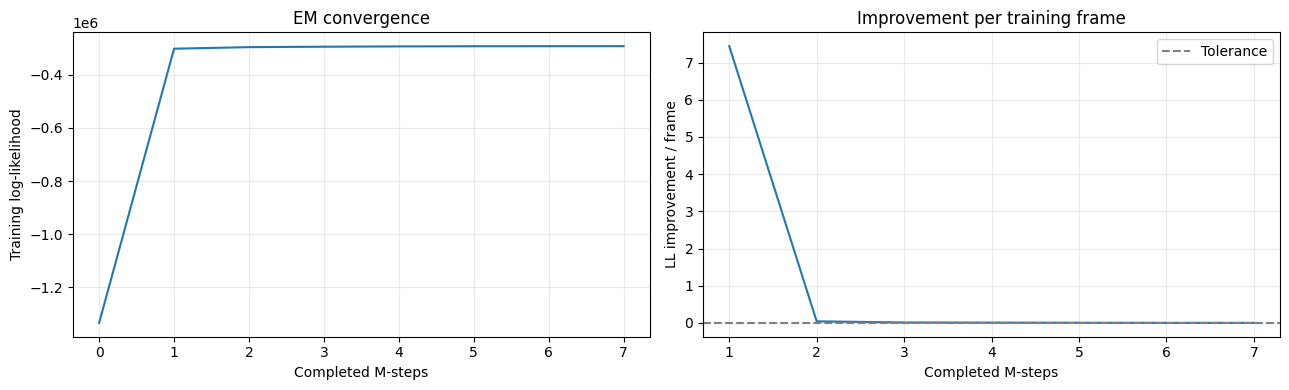

In [ ]:
# [8] Full EM training: alternate E-step and M-step until convergence.
# MAX_ITER is an upper limit, NOT a required number of iterations.
MAX_ITER = 1000
MIN_ITER = 5
TOL_PER_FRAME = 1e-5        # Minimum LL improvement per training observation
PATIENCE = 3                # Require 3 consecutive small improvements
PRINT_EVERY = 10


def fit_hmm_em(x, init_start, init_trans, init_means, init_covariances, init_extra,
               max_iter=MAX_ITER, min_iter=MIN_ITER,
               tol_per_frame=TOL_PER_FRAME, patience=PATIENCE,
               print_every=PRINT_EVERY):
    start_fit = init_start.copy()
    trans_fit = init_trans.copy()
    means_fit = init_means.copy()
    cov_fit = init_covariances.copy()
    extra_fit = {k: v.copy() if isinstance(v,np.ndarray) else v for k,v in init_extra.items()}
    n_obs = x.shape[0] * x.shape[1]

    # The first LL corresponds to the INITIAL parameters (iteration 0).
    ll_per_h, gamma, xi = forward_backward(
        x, start_fit, trans_fit, means_fit, cov_fit, extra_fit
    )
    current_ll = float(ll_per_h.sum())
    history = [{"Iteration": 0, "Train Log-Likelihood": current_ll,
                "Improvement per Frame": np.nan}]
    print(f"Iteration 0: train LL = {current_ll:.3f}")
    small_improvement_count = 0
    status = "Maximum iterations reached"

    for iteration in range(1, max_iter + 1):
        # M-step: update all HMM parameters using posterior gamma and xi.
        next_start, next_trans, next_means, next_cov, next_extra = update_hmm(
            x, gamma, xi, extra_fit
        )

        # E-step under NEW parameters: also provides the NEW log-likelihood.
        next_ll_per_h, next_gamma, next_xi = forward_backward(
            x, next_start, next_trans, next_means, next_cov, next_extra
        )
        next_ll = float(next_ll_per_h.sum())
        improvement = (next_ll - current_ll) / n_obs

        if not np.isfinite(next_ll):
            raise FloatingPointError("Non-finite log-likelihood during EM.")
        # Numerical rounding / covariance regularization can cause minor declines.
        if improvement < -1e-7:
            print(f"Warning: LL decreased at iteration {iteration}: "
                  f"{improvement:.3e} per frame. Stopping at previous parameters.")
            status = "Stopped: LL decreased"
            break

        # Accept the completed EM update.
        start_fit, trans_fit = next_start, next_trans
        means_fit, cov_fit, extra_fit = next_means, next_cov, next_extra
        current_ll, gamma, xi = next_ll, next_gamma, next_xi
        history.append({"Iteration": iteration,
                        "Train Log-Likelihood": current_ll,
                        "Improvement per Frame": improvement})

        if iteration == 1 or iteration % print_every == 0:
            print(f"Iteration {iteration}: train LL = {current_ll:.3f}; "
                  f"improvement/frame = {improvement:.3e}")

        if iteration >= min_iter and abs(improvement) < tol_per_frame:
            small_improvement_count += 1
        else:
            small_improvement_count = 0

        if small_improvement_count >= patience:
            status = f"Converged (3 consecutive improvements/frame < {tol_per_frame:g})"
            break

    return {
        "start": start_fit,
        "trans": trans_fit,
        "means": means_fit,
        "covariances": cov_fit,
        "extra": extra_fit,
        "gamma_train": gamma,
        "xi_train": xi,
        "history": pd.DataFrame(history),
        "status": status,
    }


fit = fit_hmm_em(train_x, start, trans, means, covariances, extra)
trained_start = fit["start"]
trained_trans = fit["trans"]
trained_means = fit["means"]
trained_covariances = fit["covariances"]
trained_extra = fit["extra"]
train_gamma_final = fit["gamma_train"]
train_xi_final = fit["xi_train"]
ll_history = fit["history"]

print("\nTraining status:", fit["status"])
print("Completed M-steps:", len(ll_history) - 1)
print("Initial training LL:", round(ll_history.iloc[0]["Train Log-Likelihood"], 3))
print("Final training LL:  ", round(ll_history.iloc[-1]["Train Log-Likelihood"], 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ll_history["Iteration"], ll_history["Train Log-Likelihood"])
axes[0].set(title="EM convergence", xlabel="Completed M-steps",
            ylabel="Training log-likelihood")
axes[0].grid(alpha=0.25)
axes[1].plot(ll_history["Iteration"].iloc[1:],
             ll_history["Improvement per Frame"].iloc[1:])
axes[1].axhline(TOL_PER_FRAME, linestyle="--", color="gray", label="Tolerance")
axes[1].set(title="Improvement per training frame", xlabel="Completed M-steps",
            ylabel="LL improvement / frame")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

# [9] Trained Model Summary, Held-Out Evaluation and Save


In [ ]:
# [9] Evaluate the trained HMM without refitting on the held-out test H atoms.
train_ll_final, train_gamma_final, train_xi_final = forward_backward(
    train_x, trained_start, trained_trans, trained_means, trained_covariances, trained_extra
)
test_ll_final, test_gamma_final, test_xi_final = forward_backward(
    test_x, trained_start, trained_trans, trained_means, trained_covariances, trained_extra
)

comparison = pd.DataFrame([
    {"Dataset": "Train", "H trajectories": len(train_x),
     "Frames": train_x.shape[1], "Total log-likelihood": train_ll_final.sum(),
     "Mean LL per frame": train_ll_final.sum() / train_x.shape[0] / train_x.shape[1]},
    {"Dataset": "Test", "H trajectories": len(test_x),
     "Frames": test_x.shape[1], "Total log-likelihood": test_ll_final.sum(),
     "Mean LL per frame": test_ll_final.sum() / test_x.shape[0] / test_x.shape[1]},
])
print("Train vs test likelihood (same trained model, standardized coordinates):")
display(comparison.round(4))

# Names come from learned distance gap, not from state index.
_vibration_state = int(np.argmin(trained_means[:, FEATURES.index("gap_A")]))
state_labels = ["vibration-like" if s == _vibration_state else "covalent-like"
                for s in range(N_STATES)]
print("Trained initial state probabilities:")
display(pd.DataFrame({"State": state_labels,
                      "Initial probability": trained_start}).round(5))
print("Trained transition matrix (rows = from, columns = to):")
display(pd.DataFrame(trained_trans,
                     index=[f"From {s}" for s in state_labels],
                     columns=[f"To {s}" for s in state_labels]).round(5))
print("Trained state means in standardized coordinates:")
display(pd.DataFrame(trained_means, index=state_labels, columns=FEATURES).round(4))
print("Trained state means in ORIGINAL physical units (moment summaries, not angle modes):")
means_raw = trained_means * feat_std[None, :] + feat_mean[None, :]
display(pd.DataFrame(means_raw, index=state_labels, columns=FEATURES).round(4))

for s in range(N_STATES):
    print(f"State {s} covariance (descriptive only for mixed State 1):")
    display(pd.DataFrame(trained_covariances[s], index=FEATURES,
                         columns=FEATURES).round(4))

# Posterior occupancy: share of all frames assigned in expectation to each state.
occupancy = train_gamma_final.mean(axis=(0, 1))
print("Expected training-frame occupancy:")
display(pd.DataFrame({"State": state_labels, "Posterior occupancy": occupancy}).round(4))

# Save the complete trained parameters for future event-detection code.
# This file is created in the current Colab working directory.
np.savez_compressed(
    "hmm_2state_trained.npz",
    start=trained_start,
    trans=trained_trans,
    means=trained_means,
    covariances=trained_covariances,
    gap_left=trained_extra["gap_left"], gap_right=trained_extra["gap_right"],
    gap_smooth=trained_extra["gap_smooth"],
    angle_weights=trained_extra["angle_weights"],
    angle_means=trained_extra["angle_means"],
    angle_vars=trained_extra["angle_vars"],
    feature_names=np.array(FEATURES),
    feature_mean=feat_mean,
    feature_std=feat_std,
    train_h_ids=train_ids,
    test_h_ids=test_ids,
    log_likelihood_history=ll_history["Train Log-Likelihood"].to_numpy(),
)
print("Saved: hmm_2state_trained.npz")
print("Note: state identities are statistical; proton-transfer events still require validation.")

Train vs test likelihood (same trained model, standardized coordinates):


,Dataset,H trajectories,Frames,Total log-likelihood,Mean LL per frame
0,Train,154,900,-292480.7071,-2.1103
1,Test,66,900,-128142.2532,-2.1573


Trained initial state probabilities:


,State,Initial probability
0,vibration-like,0.01609
1,covalent-like,0.98391


Trained transition matrix (rows = from, columns = to):


,To vibration-like,To covalent-like
From vibration-like,0.99743,0.00257
From covalent-like,0.00669,0.99331


... (7 outputs left out)

,r1_A,gap_A,O1_H_O2_angle_deg
r1_A,0.2562,-0.1066,0.0916
gap_A,-0.1066,0.4337,-0.5039
O1_H_O2_angle_deg,0.0916,-0.5039,1.5691


Expected training-frame occupancy:


,State,Posterior occupancy
0,vibration-like,0.6245
1,covalent-like,0.3755


Saved: hmm_2state_trained.npz
Note: state identities are statistical; proton-transfer events still require validation.


## [10] Mixed-Emission Diagnostics

The first state remains a 3D Gaussian. The upper-gap state uses a smoothed-uniform gap and a 2-component angle Gaussian mixture, **not** a trivariate Gaussian. The state-1 feature independence assumption means its covariance is descriptive rather than a fitted dependence structure.

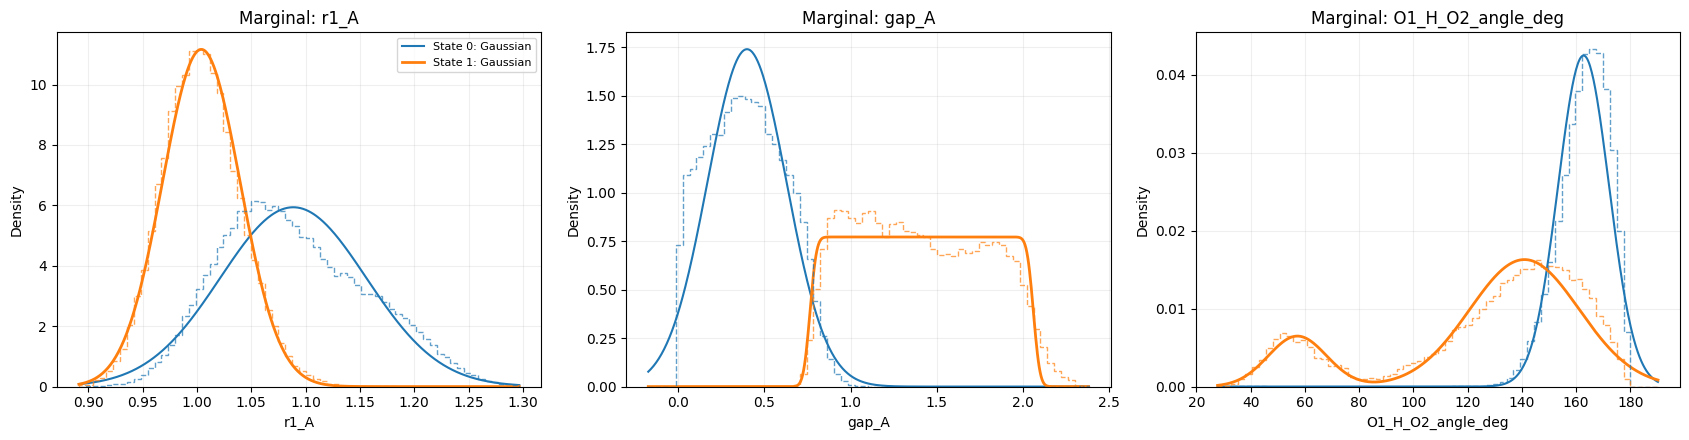

State 1 gap range (physical Å): [0.7645 2.0597]
State 1 angle peaks (physical degrees): [ 57.218 140.969]
State 1 angle component weights: [0.1748 0.8252]
Important: State 1 independence is assumed, not fitted with a Gaussian copula.


In [ ]:
# [10] Posterior-weighted empirical marginals versus the ACTUAL fitted emission PDFs.
from scipy.stats import norm
from scipy.special import ndtr
raw_flat=train_raw.reshape(-1,len(FEATURES))
posterior_flat=train_gamma_final.reshape(-1,2)
colors=['tab:blue','tab:orange']
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for j,(ax,feature) in enumerate(zip(axes,FEATURES)):
    low,high=np.quantile(raw_flat[:,j],[.002,.998]);span=max(high-low,1e-6)
    xs=np.linspace(low-.08*span,high+.08*span,500)
    bins=np.linspace(xs[0],xs[-1],65)
    # State 0 full Gaussian marginal
    mu0=trained_means[0,j]*feat_std[j]+feat_mean[j]
    sd0=np.sqrt(trained_covariances[0,j,j])*feat_std[j]
    ax.plot(xs,norm.pdf(xs,mu0,sd0),color=colors[0],label='State 0: Gaussian')
    # State 1 marginal: distribution depends on feature
    z=(xs-feat_mean[j])/feat_std[j]
    if j==GAP_IDX:
        a,b,ss=(trained_extra[k] for k in ('gap_left','gap_right','gap_smooth'))
        fitted=(ndtr((z-a)/ss)-ndtr((z-b)/ss))/(b-a)/feat_std[j]
        name='Smoothed uniform'
    elif j==ANGLE_IDX:
        fitted=sum(trained_extra['angle_weights'][k]*norm.pdf(z,trained_extra['angle_means'][k],
                     np.sqrt(trained_extra['angle_vars'][k])) for k in range(2))/feat_std[j]
        name='2-Gaussian mixture'
    else:
        mu=trained_means[1,j];sd=np.sqrt(trained_covariances[1,j,j])
        fitted=norm.pdf(z,mu,sd)/feat_std[j]
        name='Gaussian'
    ax.plot(xs,fitted,color=colors[1],lw=2,label='State 1: '+name)
    for s in range(2):
        ax.hist(raw_flat[:,j],bins=bins,weights=posterior_flat[:,s],density=True,
                histtype='step',linestyle='--',alpha=.7,color=colors[s])
    ax.set(xlabel=feature,ylabel='Density',title='Marginal: '+feature)
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.tight_layout();plt.show()
print('State 1 gap range (physical Å):', np.round(np.array([
    trained_extra['gap_left'],trained_extra['gap_right']])*feat_std[GAP_IDX]+feat_mean[GAP_IDX],4))
print('State 1 angle peaks (physical degrees):',np.round(
    trained_extra['angle_means']*feat_std[ANGLE_IDX]+feat_mean[ANGLE_IDX],3))
print('State 1 angle component weights:',np.round(trained_extra['angle_weights'],4))
print('Important: State 1 independence is assumed, not fitted with a Gaussian copula.')

# [11] Predict Covalent-like / Vibration-like States on the Held-Out Test Set

Use the trained HMM to decode **only held-out test H trajectories** using Viterbi (no parameter refitting). A smaller learned mean `gap_A` is operationally labeled **vibration-like**, and a larger mean gap **covalent-like**. These are geometry-based statistical labels, not chemical proof. No minimum duration is imposed.


In [ ]:
from scipy.special import logsumexp

def viterbi_decode(x, start, trans, means, covariances, extra):
    emission = log_emission(x, means, covariances, extra)
    n_h, n_frames, n_states = emission.shape
    delta = np.empty_like(emission)
    backpointer = np.zeros((n_h, n_frames, n_states), dtype=np.int16)
    delta[:, 0, :] = np.log(np.maximum(start, 1e-300)) + emission[:, 0, :]
    log_trans = np.log(np.maximum(trans, 1e-300))
    for t in range(1, n_frames):
        score = delta[:, t-1, :, None] + log_trans[None, :, :]
        backpointer[:, t, :] = np.argmax(score, axis=1)
        delta[:, t, :] = emission[:, t, :] + np.max(score, axis=1)
    paths = np.zeros((n_h, n_frames), dtype=np.int16)
    paths[:, -1] = np.argmax(delta[:, -1, :], axis=1)
    rows = np.arange(n_h)
    for t in range(n_frames - 2, -1, -1):
        paths[:, t] = backpointer[rows, t+1, paths[:, t+1]]
    return paths

vibration_state = int(np.argmin(trained_means[:, FEATURES.index("gap_A")]))
covalent_state = 1 - vibration_state
state_name = {vibration_state: "vibration-like", covalent_state: "covalent-like"}
print("State mapping:", state_name)

state_path = viterbi_decode(test_x, trained_start, trained_trans,
                            trained_means, trained_covariances, trained_extra)
prediction_rows = []
for h_idx, h_id in enumerate(test_ids):
    geom = by_h[h_id].sort_values("Frame").copy()
    if len(geom) != state_path.shape[1]:
        raise ValueError(f"Frame count mismatch for H_ID={h_id}")
    geom["Predicted_State"] = state_path[h_idx]
    geom["State_Type"] = [state_name[int(s)] for s in state_path[h_idx]]
    geom["P_Vibration"] = test_gamma_final[h_idx, :, vibration_state]
    geom["P_Covalent"] = test_gamma_final[h_idx, :, covalent_state]
    prediction_rows.append(geom)
state_predictions = pd.concat(prediction_rows, ignore_index=True)
print("Predicted occupancy (held-out test H trajectories):")
display(state_predictions["State_Type"].value_counts().rename_axis("State_Type")
        .reset_index(name="Frames"))

State mapping: {0: 'vibration-like', 1: 'covalent-like'}
Predicted occupancy (held-out test H trajectories):


,State_Type,Frames
0,vibration-like,40046
1,covalent-like,19354


# [12] Oxygen-Switch Candidates and Annotated O–H Distance Plots

Candidates follow **covalent-like → vibration-like → covalent-like** with different nearest oxygen IDs immediately before and after the vibration-like interval. **No minimum duration, posterior cutoff, or oxygen-persistence filter** is used. Each row records both HMM state transition frames, previous/new oxygen identities, and duration in frames. A candidate is not confirmation of proton transfer.

Figures show the complete held-out H trajectory, with the **two nearest oxygens at each frame** as colored points (color = oxygen identity). Vertical lines annotate the beginning and end of the vibration-like interval. The closest-two-oxygen membership can change between frames, as in the reference plot. To avoid excessive figures, `PLOT_LIMIT` can be set to a positive number; `None` shows every candidate-bearing H.


In [ ]:
# [12A] Extract all candidates: no arbitrary lifetime thresholds.
def contiguous_runs(states):
    cuts = np.r_[0, np.flatnonzero(states[1:] != states[:-1]) + 1, len(states)]
    return [(int(states[a]), int(a), int(b)) for a, b in zip(cuts[:-1], cuts[1:])]

def find_oxygen_switch_candidates(predictions, vibration, covalent):
    rows = []
    for h_id, group in predictions.groupby("H_ID", sort=True):
        g = group.sort_values("Frame").reset_index(drop=True)
        st = g["Predicted_State"].to_numpy(dtype=int)
        oxy = g["O1_ID"].to_numpy(dtype=int)
        fr = g["Frame"].to_numpy(dtype=int)
        posterior = g["P_Vibration"].to_numpy(dtype=float)
        runs = contiguous_runs(st)
        for j in range(1, len(runs)-1):
            (a_s, a0, a1), (b_s, b0, b1), (c_s, c0, c1) = runs[j-1:j+2]
            if (a_s, b_s, c_s) != (covalent, vibration, covalent):
                continue
            donor, acceptor = int(oxy[a1-1]), int(oxy[c0])
            if donor == acceptor:
                continue
            rows.append({
                "H_ID": int(h_id), "O_before": donor, "O_after": acceptor,
                "Covalent_before_start": int(fr[a0]),
                "Covalent_before_end": int(fr[a1-1]),
                "Covalent_before_frames": int(a1-a0),
                "Switch_to_vibration_frame": int(fr[b0]),
                "Vibration_end_frame": int(fr[b1-1]),
                "Vibration_frames": int(b1-b0),
                "Switch_to_covalent_frame": int(fr[c0]),
                "Covalent_after_end": int(fr[c1-1]),
                "Covalent_after_frames": int(c1-c0),
                "P_Vibration_max": float(posterior[b0:b1].max()),
            })
    columns = ["H_ID", "O_before", "O_after", "Covalent_before_start",
               "Covalent_before_end", "Covalent_before_frames",
               "Switch_to_vibration_frame", "Vibration_end_frame",
               "Vibration_frames", "Switch_to_covalent_frame",
               "Covalent_after_end", "Covalent_after_frames", "P_Vibration_max"]
    return pd.DataFrame(rows, columns=columns).sort_values(
        ["H_ID", "Switch_to_vibration_frame"]
    ).reset_index(drop=True)

oxygen_switch_candidates = find_oxygen_switch_candidates(
    state_predictions, vibration_state, covalent_state
)
print(f"Covalent → vibration → covalent candidates (test H only): {len(oxygen_switch_candidates)}")
display(oxygen_switch_candidates.round(3))
state_predictions.to_csv("hmm_test_h_state_predictions.csv", index=False)
oxygen_switch_candidates.to_csv("hmm_oxygen_switch_candidates.csv", index=False)
print("Saved predictions and candidate CSV files.")


Covalent → vibration → covalent candidates (test H only): 8


,H_ID,O_before,O_after,Covalent_before_start,Covalent_before_end,Covalent_before_frames,Switch_to_vibration_frame,Vibration_end_frame,Vibration_frames,Switch_to_covalent_frame,Covalent_after_end,Covalent_after_frames,P_Vibration_max
0,11,10,224,239,254,16,255,617,363,618,900,283,1.0
1,97,95,266,1,210,210,211,600,390,601,618,18,1.0
2,97,266,95,601,618,18,619,871,253,872,900,29,1.0
3,181,179,89,1,25,25,26,821,796,822,847,26,1.0
4,211,209,152,1,31,31,32,829,798,830,900,71,1.0
5,226,224,263,253,263,11,264,836,573,837,900,64,1.0
6,231,230,77,134,157,24,158,822,665,823,829,7,1.0
7,270,269,272,534,584,51,585,801,217,802,827,26,1.0


Saved predictions and candidate CSV files.


Generating plots for 7/7 candidate-bearing H atoms


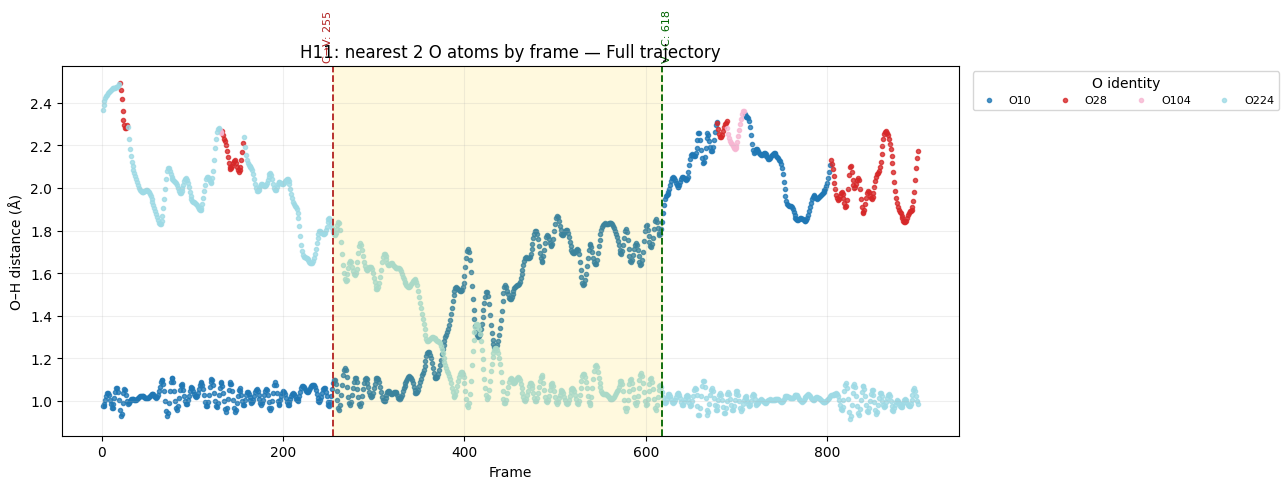

H11: state transitions (frame of NEW state)


,O_before,O_after,Switch_to_vibration_frame,Switch_to_covalent_frame,Vibration_frames,Covalent_before_frames,Covalent_after_frames
0,10,224,255,618,363,16,283


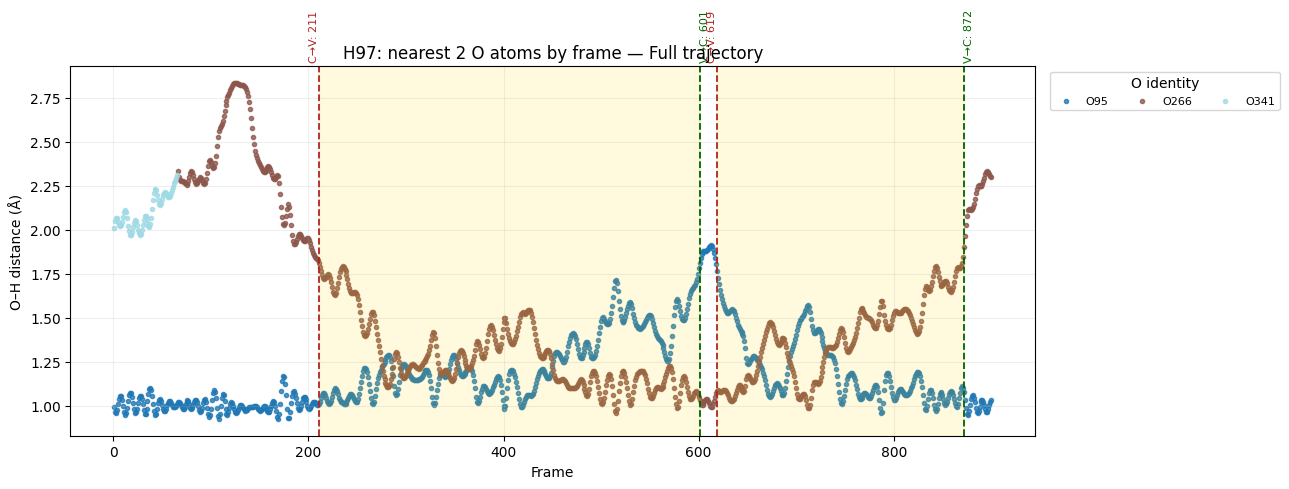

H97: state transitions (frame of NEW state)


,O_before,O_after,Switch_to_vibration_frame,Switch_to_covalent_frame,Vibration_frames,Covalent_before_frames,Covalent_after_frames
0,95,266,211,601,390,210,18
1,266,95,619,872,253,18,29


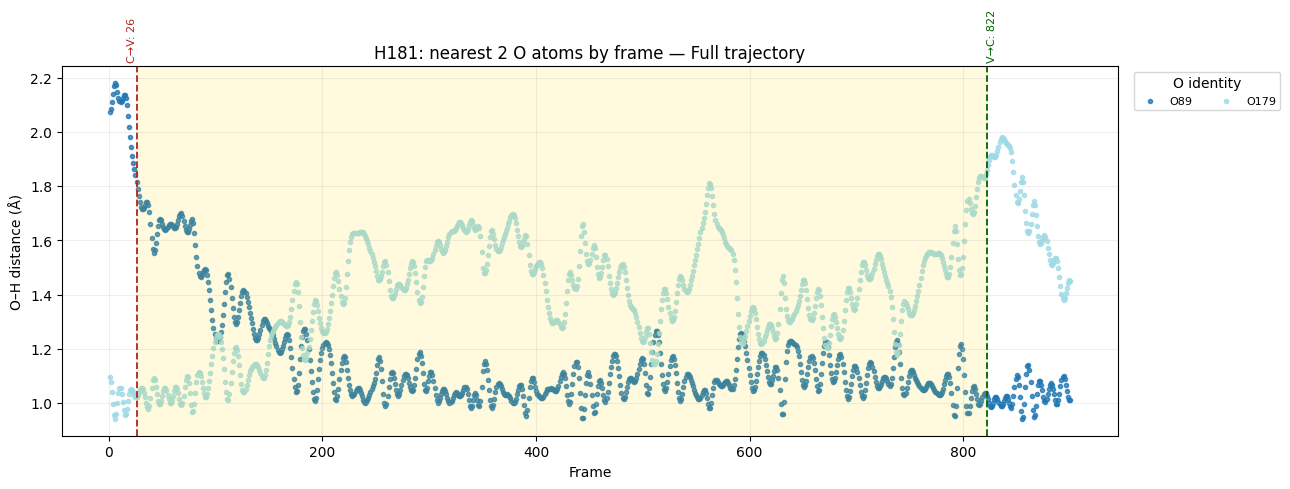

H181: state transitions (frame of NEW state)


,O_before,O_after,Switch_to_vibration_frame,Switch_to_covalent_frame,Vibration_frames,Covalent_before_frames,Covalent_after_frames
0,179,89,26,822,796,25,26


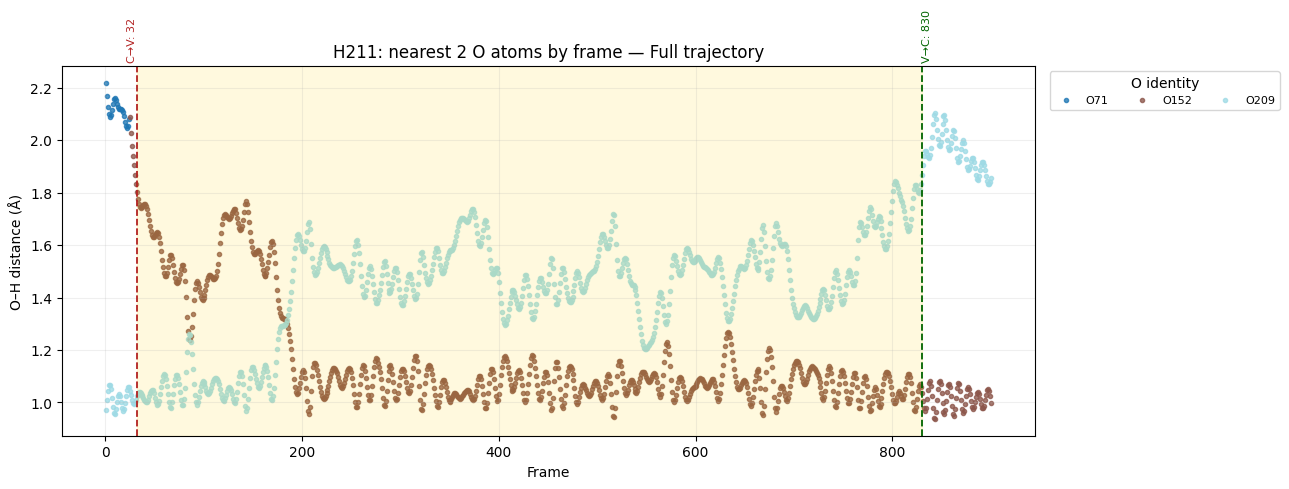

H211: state transitions (frame of NEW state)


,O_before,O_after,Switch_to_vibration_frame,Switch_to_covalent_frame,Vibration_frames,Covalent_before_frames,Covalent_after_frames
0,209,152,32,830,798,31,71


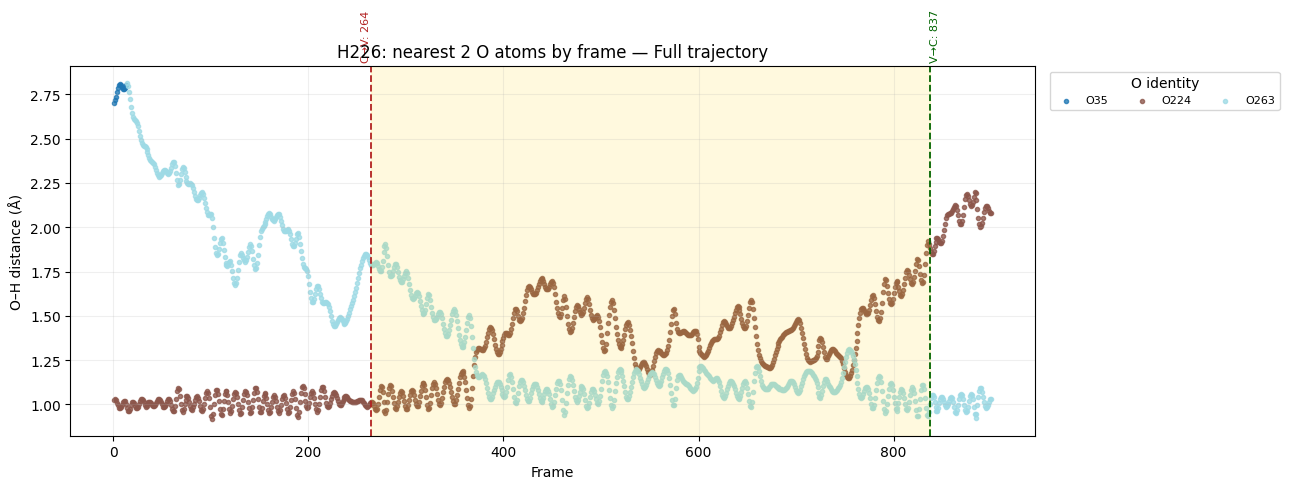

H226: state transitions (frame of NEW state)


,O_before,O_after,Switch_to_vibration_frame,Switch_to_covalent_frame,Vibration_frames,Covalent_before_frames,Covalent_after_frames
0,224,263,264,837,573,11,64


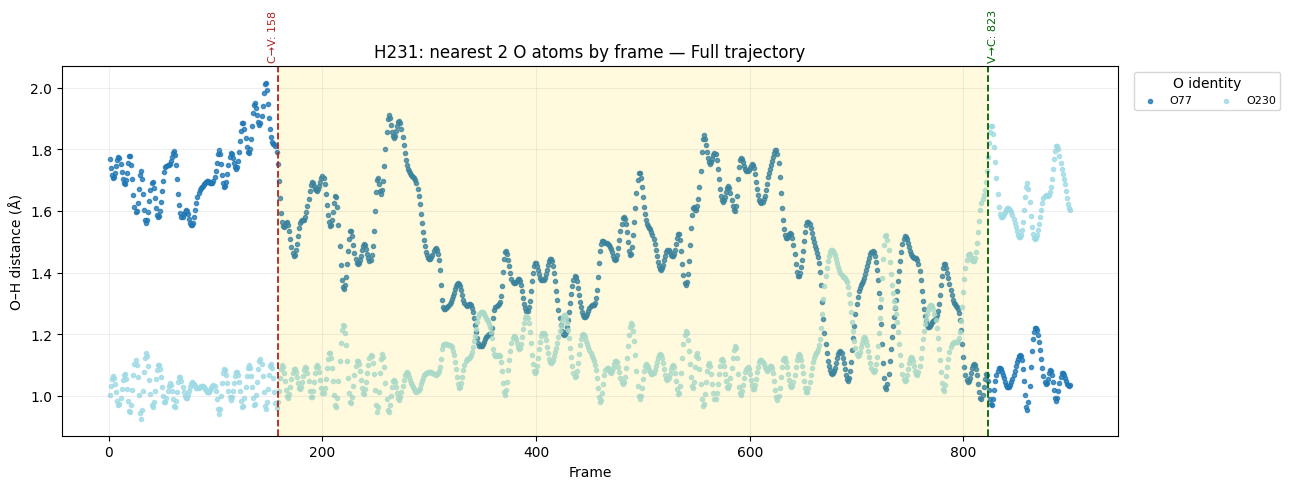

H231: state transitions (frame of NEW state)


,O_before,O_after,Switch_to_vibration_frame,Switch_to_covalent_frame,Vibration_frames,Covalent_before_frames,Covalent_after_frames
0,230,77,158,823,665,24,7


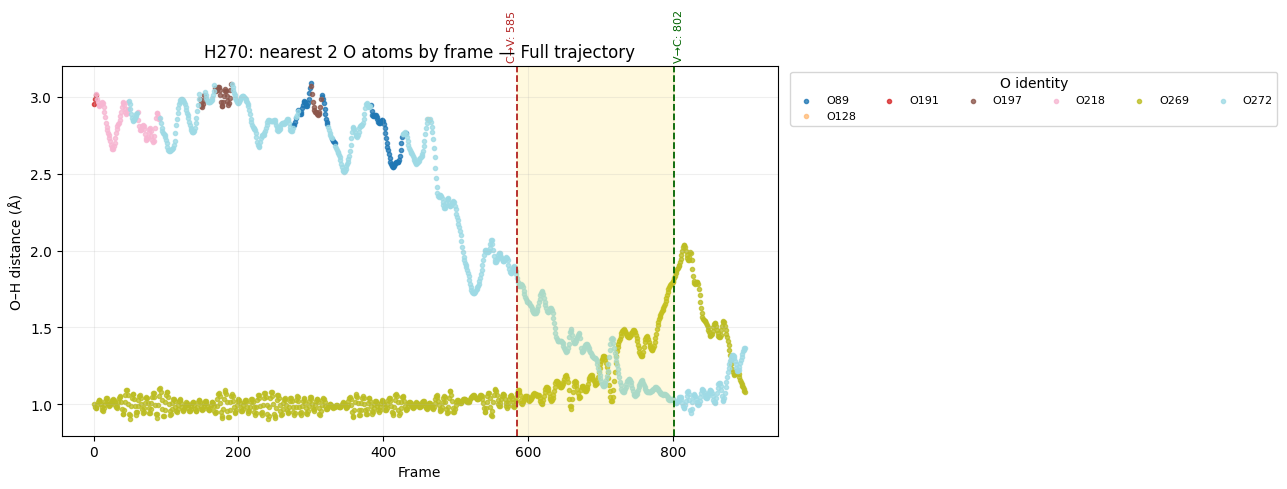

H270: state transitions (frame of NEW state)


,O_before,O_after,Switch_to_vibration_frame,Switch_to_covalent_frame,Vibration_frames,Covalent_before_frames,Covalent_after_frames
0,269,272,585,802,217,51,26


In [ ]:
# [12B] Plot nearest-two O distances, colored by oxygen identity, with state switches.
# None = plot all H atoms having a candidate. Set e.g. 5 to inspect the first 5.
PLOT_LIMIT = None
PLOT_FULL_TRAJECTORY = True  # False: crop around each event using PLOT_CONTEXT_FRAMES
PLOT_CONTEXT_FRAMES = 80

from matplotlib.lines import Line2D

def plot_oxygen_candidate(h_id, candidates, predictions, full=True, context=80):
    g = predictions.loc[predictions["H_ID"] == h_id].sort_values("Frame")
    if g.empty:
        return
    relevant = candidates.loc[candidates["H_ID"] == h_id]
    if relevant.empty:
        return
    # Scatter only the two nearest O per frame, respecting O_ID rather than r1/r2 rank.
    long_o = pd.concat([
        g[["Frame", "O1_ID", "r1_A"]].rename(columns={"O1_ID": "O_ID", "r1_A": "Distance_A"}),
        g[["Frame", "O2_ID", "r2_A"]].rename(columns={"O2_ID": "O_ID", "r2_A": "Distance_A"}),
    ], ignore_index=True)
    if full:
        views = [(long_o, relevant, "Full trajectory")]
    else:
        views = []
        for _, e in relevant.iterrows():
            lo = int(e["Switch_to_vibration_frame"] - context)
            hi = int(e["Switch_to_covalent_frame"] + context)
            views.append((long_o.loc[long_o["Frame"].between(lo, hi)],
                          pd.DataFrame([e]), f"Frames {lo}–{hi}"))
    for subset, ev, caption in views:
        fig, ax = plt.subplots(figsize=(13, 5))
        o_ids = sorted(subset["O_ID"].unique())
        palette = plt.get_cmap("tab20", max(1, len(o_ids)))
        for j, oid in enumerate(o_ids):
            points = subset.loc[subset["O_ID"] == oid]
            ax.scatter(points["Frame"], points["Distance_A"],
                       s=9, alpha=0.78, color=palette(j), label=f"O{oid}", rasterized=True)
        for k, (_, e) in enumerate(ev.iterrows()):
            t1 = int(e["Switch_to_vibration_frame"])
            t2 = int(e["Switch_to_covalent_frame"])
            ax.axvspan(t1, t2, color="gold", alpha=.13)
            ax.axvline(t1, color="firebrick", ls="--", lw=1.3)
            ax.axvline(t2, color="darkgreen", ls="--", lw=1.3)
            ax.text(t1, 1.01, f"C→V: {t1}", rotation=90, fontsize=8,
                    ha="right", va="bottom", color="firebrick",
                    transform=ax.get_xaxis_transform())
            ax.text(t2, 1.01, f"V→C: {t2}", rotation=90, fontsize=8,
                    ha="left", va="bottom", color="darkgreen",
                    transform=ax.get_xaxis_transform())
        ax.set(title=f"H{h_id}: nearest 2 O atoms by frame — {caption}",
               xlabel="Frame", ylabel="O–H distance (Å)")
        ax.grid(alpha=.2)
        ax.legend(title="O identity", ncol=min(6, max(1, len(o_ids))),
                  fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
        plt.tight_layout()
        plt.show()
    print(f"H{h_id}: state transitions (frame of NEW state)")
    display(relevant[["O_before", "O_after", "Switch_to_vibration_frame",
                      "Switch_to_covalent_frame", "Vibration_frames",
                      "Covalent_before_frames", "Covalent_after_frames"]].reset_index(drop=True))

candidate_h_ids = oxygen_switch_candidates["H_ID"].drop_duplicates().tolist()
selected_h_ids = candidate_h_ids if PLOT_LIMIT is None else candidate_h_ids[:PLOT_LIMIT]
print(f"Generating plots for {len(selected_h_ids)}/{len(candidate_h_ids)} candidate-bearing H atoms")
for h_id in selected_h_ids:
    plot_oxygen_candidate(h_id, oxygen_switch_candidates,
                          state_predictions, full=PLOT_FULL_TRAJECTORY,
                          context=PLOT_CONTEXT_FRAMES)
